In [2]:
from pathlib import Path
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, AutoMinorLocator
import seaborn as sns
import json
import re
import pandas as pd
import numpy as np
from torchmetrics import AUROC

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

data_path = Path('../data')

## Pretraining epoch ablation

In [38]:
results = pd.read_csv(data_path / 'pretrain-ablation_results.csv')
results.head()


,model,pretrained_epoch,method,run_id,auroc
0,vit-b,10,full_finetune,3,0.677752
1,vit-s,60,full_finetune,0,0.956157
2,vit-b,100,full_finetune,3,0.819512
3,vit-s,90,full_finetune,2,0.988305
4,vit-s,10,full_finetune,3,0.769637


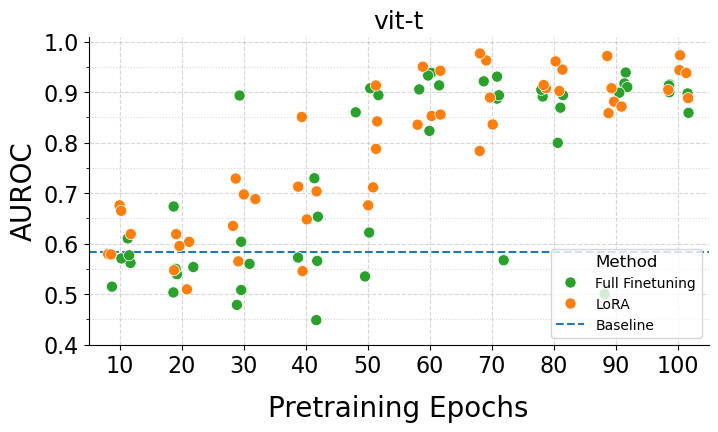

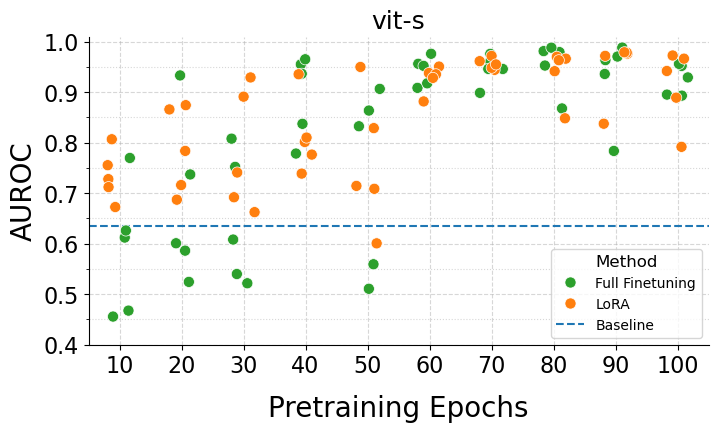

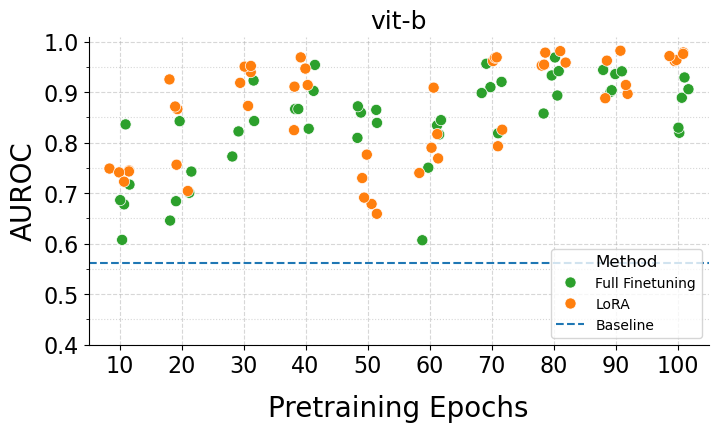

In [31]:
median_supervised = {
    'vit-t': np.median([0.60547, 0.58245, 0.60421, 0.54754, 0.56913]),
    'vit-s': np.median([0.75879212, 0.63476242, 0.62351866, 0.59591059, 0.72331323]),
    'vit-b': np.median([0.52947, 0.56124, 0.62413, 0.53785, 0.63945])
}
for model in ['vit-t', 'vit-s', 'vit-b']:
    f, ax = plt.subplots(figsize=(8, 4))
    to_plot = results[results['model'] == model].copy()
    to_plot['method'] = to_plot['method'].replace({'lora': 'LoRA', 'full_finetune': 'Full Finetuning'})
    sns.stripplot(data=to_plot,
                x='pretrained_epoch',
                y='auroc',
                hue='method',
                palette={'LoRA':'tab:orange', 'Full Finetuning':'tab:green'},
                s=8,
                dodge=False,
                edgecolor='white',
                linewidth=0.5,
                jitter=0.2,
                legend=True,
                ax=ax)
    # add blue line with mean supervised performance
    ax.axhline(median_supervised[model], color='tab:blue', linestyle='--', label='Baseline')
    plt.xlabel('Pretraining Epochs', fontsize=20, labelpad=12)
    plt.xticks(fontsize=16)
    plt.ylabel('AUROC', fontsize=20)
    plt.yticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], fontsize=16)
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_ylim(0.4, 1.01)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # plt.xscale('log')
    ax.grid(True, which='major', axis='both', linestyle='--', alpha=0.5)
    ax.grid(True, which='minor', axis='both', linestyle=':', alpha=0.5)
    plt.title(f'{model}', fontsize=18)
    plt.legend(title='Method', loc='lower right', fontsize=10, title_fontsize=12)
    plt.show()

## Finetuning set size ablation

In [36]:
results = pd.read_csv(data_path / 'finetune-ablation_results.csv')
results.head()

,model,method,split,n_cbcts,run,auroc
0,vit-b,fullft,1,2739,3,0.528608
1,vit-s,fullft,3,8091,3,0.939455
2,vit-b,fullft,3,8091,3,0.819512
3,vit-b,fullft,7,19134,2,0.932954
4,vit-b,fullft,1,2739,1,0.885943


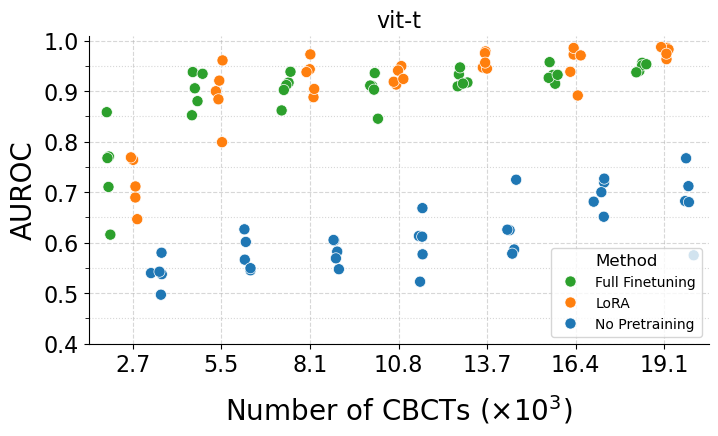

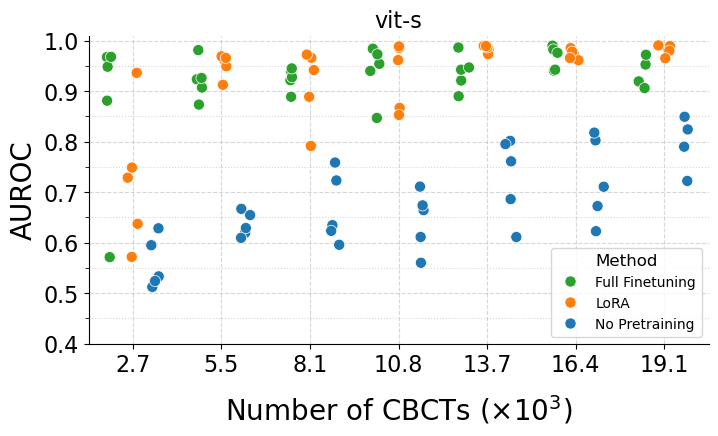

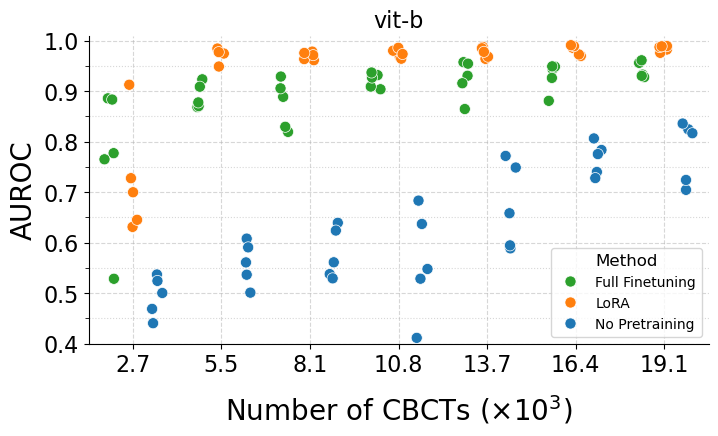

In [37]:
for model in ['vit-t', 'vit-s', 'vit-b']:
    f, ax = plt.subplots(figsize=(8, 4))
    to_plot = results[results['model'] == model].copy()
    to_plot['method'] = to_plot['method'].replace({'lora':'LoRA',
                                            'fullft': 'Full Finetuning',
                                            'sup':'No Pretraining'})
    to_plot.sort_values(by=['n_cbcts', 'method'], ascending=True, inplace=True)
    sns.stripplot(data=to_plot,
                x='n_cbcts',
                y='auroc',
                hue='method',
                palette={'LoRA':'tab:orange',
                        'Full Finetuning':'tab:green',
                        'No Pretraining':'tab:blue'},
                s=8,
                dodge=True,
                edgecolor='white',
                linewidth=0.5,
                legend=True,
                jitter=0.2,
                ax=ax
                )
    plt.xlabel(r'Number of CBCTs ($\times 10^3$)', fontsize=20, labelpad=12)
    plt.ylabel('AUROC', fontsize=20)
    plt.xticks(ax.get_xticks(), ['2.7', '5.5', '8.1', '10.8', '13.7', '16.4', '19.1'], fontsize=16)
    plt.yticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], fontsize=16)
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_ylim(0.4, 1.01)
    ax.tick_params(axis='y', which='minor', length=3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, which='major', axis='both', linestyle='--', alpha=0.5)
    ax.grid(True, which='minor', axis='both', linestyle=':', alpha=0.5)
    plt.title(f'{model}', fontsize=16)
    plt.legend(title='Method', loc='lower right', fontsize=10, title_fontsize=12)
    plt.show()

## Clinical downstream

In [41]:
results = pd.read_csv(data_path / 'finetune_clinical_results.csv')
results.drop(columns=['experiment_name'], inplace=True)
results.task.unique()

array(['age-regr', 'n-stage-class', 'sex-class', 't-stage-class',
       'tumorsite-class'], dtype=object)

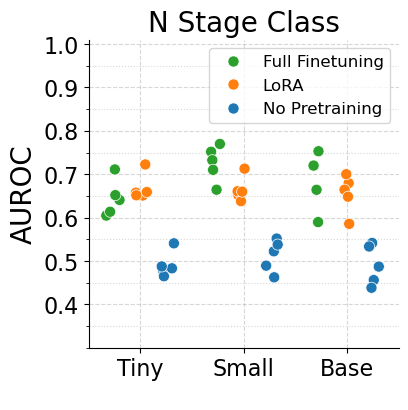

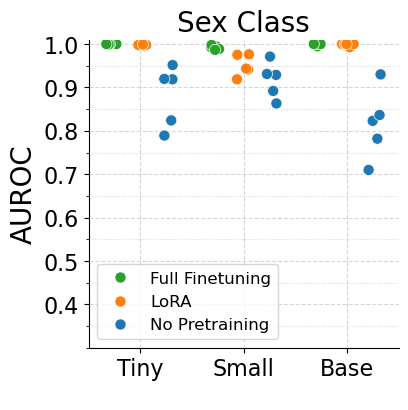

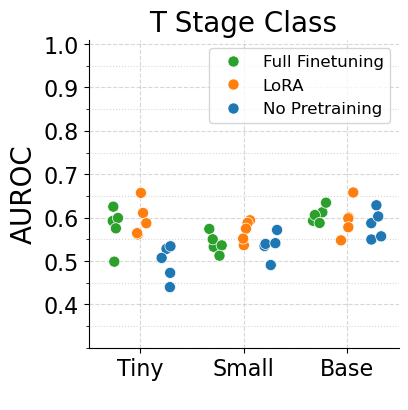

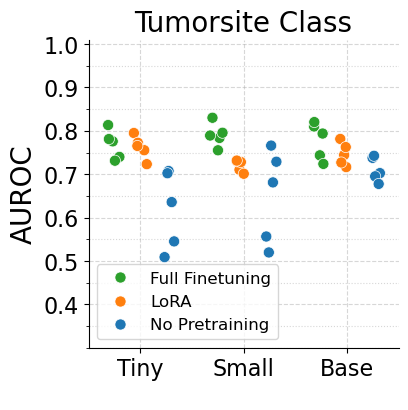

In [43]:
for task_name in ['n-stage-class', 'sex-class', 't-stage-class', 'tumorsite-class']:
    f, ax = plt.subplots(figsize=(4, 4))
    to_plot = results.loc[(results['task'] == task_name)].copy()
    to_plot['method'] = to_plot['method'].replace(
        {'lora': 'LoRA', 'fullft': 'Full Finetuning', 'sup': 'No Pretraining'})
    to_plot['model'] = to_plot['model'].replace({'vit-s': 'Small', 'vit-t': 'Tiny', 'vit-b': 'Base'})
    to_plot.sort_values(by=['method', 'model'], ascending=False, inplace=True)

    sns.stripplot(data=to_plot,
                x='model',
                y='auroc',
                hue='method',
                hue_order=['Full Finetuning', 'LoRA', 'No Pretraining'],
                palette={'LoRA':'tab:orange',
                        'Full Finetuning':'tab:green',
                        'No Pretraining':'tab:blue'},
                s=8,
                dodge=True,
                edgecolor='white',
                linewidth=0.5,
                legend=True,
                jitter=0.2,
                ax=ax
                )
    plt.ylabel('AUROC', fontsize=20)
    plt.yticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], fontsize=16)
    ax.set_ylim(0.3, 1.01)
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    plt.xlabel('Model', color='white')
    plt.xticks(fontsize=16)
    ax.grid(True, which='major', axis='both', linestyle='--', alpha=0.5)
    ax.grid(True, which='minor', axis='both', linestyle=':', alpha=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.title(task_name.replace('-', ' ').title(), fontsize=20)
    plt.legend(fontsize=12)

    plt.show()

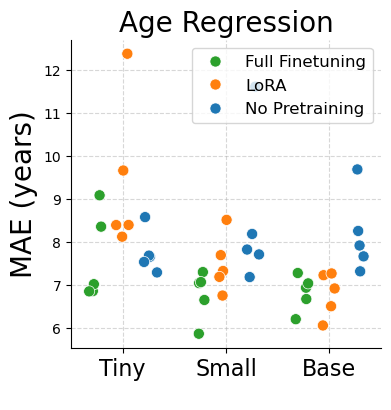

In [46]:
f, ax = plt.subplots(figsize=(4, 4))
to_plot = results.loc[(results['task'] == 'age-regr')].copy()
to_plot['method'] = to_plot['method'].replace(
    {'lora': 'LoRA', 'fullft': 'Full Finetuning', 'sup': 'No Pretraining'})
to_plot['model'] = to_plot['model'].replace({'vit-s': 'Small', 'vit-t': 'Tiny', 'vit-b': 'Base'})
to_plot.sort_values(by=['method', 'model'], ascending=False, inplace=True)

sns.stripplot(data=to_plot,
            x='model',
            y='mae_years',
            hue='method',
            hue_order=['Full Finetuning', 'LoRA', 'No Pretraining'],
            palette={'LoRA':'tab:orange',
                    'Full Finetuning':'tab:green',
                    'No Pretraining':'tab:blue'},
            s=8,
            dodge=True,
            edgecolor='white',
            linewidth=0.5,
            legend=True,
            jitter=0.2,
            ax=ax
            )
plt.ylabel('MAE (years)', fontsize=20)
plt.xlabel('Model', color='white')
plt.xticks(fontsize=16)
ax.grid(True, which='major', axis='both', linestyle='--', alpha=0.5)
ax.grid(True, which='minor', axis='both', linestyle=':', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.title('Age Regression', fontsize=20)
plt.legend(fontsize=12)

plt.show()